# Notebook_2v — Experimentos de otimização de tanques

Versão com os casos de um tanque **sem regularização** e **com regularização de Tikhonov**, seguidos do experimento de dois tanques.

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
from scipy.optimize import minimize

# Os gráficos são exibidos diretamente no notebook.
%matplotlib inline

MODELO_TANQUE = {
    "A": np.pi,        # Área da seção transversal [m²].
    "AE": 0.0230749,   # Ganho da válvula de entrada [m³/(s.V)].
    "BE": 0.0001068,   # Offset da vazão de entrada [m³/s].
    "KS": 0.0190001,   # Coeficiente da válvula de saída [m^(5/2)/(s.V)].
}

# =====================================================================
# 2. LIMITES FÍSICOS E OPERACIONAIS
# =====================================================================
LIMITES = {
    "H_MIN": 0.15,       # Nível mínimo permitido [m].
    "H_MAX": 3.00,       # Nível máximo permitido [m].
    "H_REF": 2.00,       # Nível desejado [m].
    "U_MIN": 2.00,       # Tensão mínima das válvulas [V].
    "U_MAX": 10.00,      # Tensão máxima das válvulas [V].
    "QE_MAX_IND": 0.25,  # Vazão máxima individual de entrada [m³/s].
    "QS_MAX_IND": 0.3543,# Vazão máxima individual de saída [m³/s].
    "QE_MAX_COMP": 0.40, # Limite compartilhado de entrada no caso de 2 tanques [m³/s].
}

# =====================================================================
# 3. DISCRETIZAÇÃO E HORIZONTE DE PREVISÃO
# =====================================================================
SIMULACAO = {
    "DT": 1.0,  # Passo de tempo da simulação [s].
    "NP": 5,    # Número de passos futuros previstos pelo otimizador.
}

# =====================================================================
# 4. CONFIGURAÇÃO DO ALGORITMO DE OTIMIZAÇÃO (SLSQP)
# =====================================================================
# maxiter: máximo de iterações internas por chamada ao SLSQP.
# ftol: tolerância dos critérios de parada.
# eps: passo de diferenças finitas para derivadas numéricas. None significa
#      deixar o SciPy usar seu valor padrão, como na versão anterior.
# disp: exibir mensagens do solver no terminal.
SLSQP = {
    "maxiter_1_tanque": 200,
    "maxiter_2_tanques": 250,
    "ftol": 1e-8,
    "eps": None,
    "disp": False,
    "avisar_se_nao_convergir": True,
}

# =====================================================================
# 5. PESOS DAS FUNÇÕES OBJETIVO (formulação do problema)
# =====================================================================
# Alterar estes pesos muda as prioridades operacionais do problema.
PESOS_OBJETIVO = {
    "um_tanque": {
        "nivel": 1.0,
        "demanda": 1e5,
        "nivel_slack": 1e8,
    },
    "dois_tanques": {
        "nivel_t1": 100.0,
        "nivel_t2": 10.0,
        "demanda_t1": 1e6,
        "demanda_t2": 20.0,
        "nivel_slack": 1e8,
    },
}

# =====================================================================
# 6. CENÁRIOS DOS EXPERIMENTOS (não são parâmetros do solver)
# =====================================================================
CENARIO_1_TANQUE = {
    "duracao": 120,             # Duração total [s].
    "nivel_inicial": 0.80,      # Nível inicial [m].
    "comando_inicial": (5.0, 5.0),  # (entrada, saída) [V].
    "blocos_demanda": ((70, 0.100), (50, 0.160)),  # (duração [s], demanda [m³/s]).
}

CENARIO_2_TANQUES = {
    "duracao": 180,
    "niveis_iniciais": (0.80, 0.80),
    # Ordem: entrada T1, entrada T2, saída T1, saída T2 [V].
    "comandos_iniciais": (5.0, 5.0, 4.0, 4.0),
    # Cada tupla representa duração [s] e demanda [L/s] do respectivo tanque.
    "blocos_demanda_t1": ((60, 90.0), (60, 230.0), (60, 90.0)),
    "blocos_demanda_t2": ((60, 80.0), (60, 180.0), (60, 80.0)),
}


A = MODELO_TANQUE["A"]
AE = MODELO_TANQUE["AE"]
BE = MODELO_TANQUE["BE"]
KS = MODELO_TANQUE["KS"]
DT = SIMULACAO["DT"]


def vazao_entrada(u_entrada):
    """Calcula a vazão de entrada [m³/s] a partir da tensão [V]."""
    return AE * np.asarray(u_entrada) + BE


def vazao_saida(nivel, u_saida):
    """Calcula a vazão de saída [m³/s] a partir do nível [m] e tensão [V]."""
    nivel_seguro = np.maximum(np.asarray(nivel), 1e-6)
    return KS * np.asarray(u_saida) * np.sqrt(nivel_seguro)


def derivada_nivel(nivel, u_entrada, u_saida):
    """Equação diferencial do nível: dh/dt = (q_entrada-q_saida)/A."""
    return (vazao_entrada(u_entrada) - vazao_saida(nivel, u_saida)) / A


def integrar_rk4(nivel, u_entrada, u_saida, dt=DT):
    """Integra um tanque por um passo usando Runge-Kutta de 4ª ordem.

    Este integrador representa a evolução efetiva da planta simulada.
    A previsão interna do otimizador continua usando Euler, como no código
    anterior, para preservar exatamente a abordagem já adotada.
    """
    f = lambda h: derivada_nivel(h, u_entrada, u_saida)
    k1 = f(nivel)
    k2 = f(nivel + 0.5 * dt * k1)
    k3 = f(nivel + 0.5 * dt * k2)
    k4 = f(nivel + dt * k3)
    return max(0.0, float(nivel + dt * (k1 + 2*k2 + 2*k3 + k4) / 6.0))


def prever_um_tanque_euler(nivel_inicial, comandos_entrada, comandos_saida, dt=DT):
    """Prevê níveis e vazões de saída em NP passos usando Euler explícito.

    Retorna níveis com NP+1 amostras (incluindo a condição inicial), vazões
    de saída, vazões de entrada e os vetores de comandos recebidos.
    """
    ue = np.asarray(comandos_entrada, dtype=float)
    us = np.asarray(comandos_saida, dtype=float)
    niveis = [float(nivel_inicial)]
    q_entrada_prev = []
    q_saida_prev = []

    for j in range(len(ue)):
        qi = float(vazao_entrada(ue[j]))
        qo = float(vazao_saida(niveis[-1], us[j]))
        q_entrada_prev.append(qi)
        q_saida_prev.append(qo)
        niveis.append(niveis[-1] + dt * (qi - qo) / A)

    return (np.asarray(niveis), np.asarray(q_entrada_prev),
            np.asarray(q_saida_prev), ue, us)


def prever_dois_tanques_euler(niveis_iniciais, comandos, dt=DT):
    """Prevê dois tanques independentes hidraulicamente, com entradas acopladas
    posteriormente por uma restrição de capacidade compartilhada no problema
    de otimização.

    Cada linha de comandos tem a ordem [ue1, ue2, us1, us2].
    """
    U = np.asarray(comandos, dtype=float)
    niveis = [np.asarray(niveis_iniciais, dtype=float).copy()]
    q_entrada_prev = []
    q_saida_prev = []

    for j in range(len(U)):
        qi = vazao_entrada(U[j, :2])
        qo = vazao_saida(niveis[-1], U[j, 2:])
        q_entrada_prev.append(qi)
        q_saida_prev.append(qo)
        niveis.append(niveis[-1] + dt * (qi - qo) / A)

    return (np.asarray(niveis), np.asarray(q_entrada_prev),
            np.asarray(q_saida_prev), U)


def resolver_slsqp(funcao_objetivo, chute_inicial, limites_variaveis,
                   restricoes, maxiter, nome_problema="problema"):
    """Resolve um problema com SLSQP e devolve o resultado original do SciPy.

    A função centraliza as opções do algoritmo para que as simulações dos
    tanques não precisem repetir a configuração do solver.
    """
    options = {
        "maxiter": int(maxiter),
        "ftol": float(SLSQP["ftol"]),
        "disp": bool(SLSQP["disp"]),
    }

    if SLSQP["eps"] is not None:
        options["eps"] = float(SLSQP["eps"])

    resultado = minimize(
        funcao_objetivo,
        chute_inicial,
        method="SLSQP",
        bounds=limites_variaveis,
        constraints=restricoes,
        options=options,
    )

    if SLSQP["avisar_se_nao_convergir"] and not resultado.success:
        warnings.warn(
            f"SLSQP não declarou convergência em {nome_problema}: "
            f"{resultado.message} (iterações={resultado.nit}, "
            f"função objetivo={resultado.fun:.6g}).",
            RuntimeWarning,
        )

    return resultado


# Valores de configuração usados diretamente nas funções dos experimentos.
NP = SIMULACAO["NP"]
DT = SIMULACAO["DT"]
H_MIN, H_MAX, H_REF = LIMITES["H_MIN"], LIMITES["H_MAX"], LIMITES["H_REF"]
U_MIN, U_MAX = LIMITES["U_MIN"], LIMITES["U_MAX"]
QE_MAX_IND, QS_MAX_IND = LIMITES["QE_MAX_IND"], LIMITES["QS_MAX_IND"]

def montar_demanda(blocos):
    """Converte blocos (duração, vazão) em um vetor de demandas [m³/s]."""
    return np.concatenate([np.full(int(duracao), float(q)) for duracao, q in blocos])


# =====================================================================

## Experimento 1 — Um tanque

**Função objetivo (sem regularização):**

\[
  \begin{aligned}
\min J_1=\sum_{j=1}^{N_p}(h_j-h_{ref})^2+10^5s_{dem}^2+10^8s_{niv}^2.
\end{aligned}
\]

**Sujeito a:**

\[
\begin{aligned}
q_{e,j}&=A_Eu_{e,j}+B_E, & q_{s,j}&=K_su_{s,j}\sqrt{h_{j-1}},\\
h_j&=h_{j-1}+\frac{\Delta t}{A}(q_{e,j}-q_{s,j}), & h_0&=h(k),\\
h_{min}-s_{niv}&\le h_j\le h_{max}+s_{niv},\\
2&\le u_{e,j},u_{s,j}\le10,\\
q_{e,j}&\le0.25, & q_{s,j}&\le0.3543,\\
q_d(k)-s_{dem}&\le q_{s,j}\le q_d(k)+s_{dem},\\
0&\le s_{dem}\le2, & 0&\le s_{niv}\le5.
\end{aligned}
\]


In [25]:
# EXPERIMENTO 1 — UM TANQUE
# =====================================================================
def simular_1_tanque():
    cfg = CENARIO_1_TANQUE
    pesos = PESOS_OBJETIVO["um_tanque"]
    T = cfg["duracao"]
    demanda = montar_demanda(cfg["blocos_demanda"])

    # Estado inicial e histórico.
    h = float(cfg["nivel_inicial"])
    u_ant = np.asarray(cfg["comando_inicial"], dtype=float)
    H = [h]
    Qe, Qs, Ue, Us = [], [], [], []

    for k in range(T):
        qd = demanda[k]

        # Vetor de decisão:
        # [ue(1..NP), us(1..NP), s_dem, s_niv].
        # O otimizador escolhe uma sequência futura de comandos e folgas.
        x0 = np.r_[
            np.full(NP, u_ant[0]),
            np.full(NP, u_ant[1]),
            qd,
            max(0.0, H_MIN - h + 0.05),
        ]

        # -------------------------------------------------------------
        # FORMULAÇÃO DO PROBLEMA: PREVISÃO, OBJETIVO E RESTRIÇÕES
        # -------------------------------------------------------------
        def decompor_decisao(x):
            ue = x[:NP]
            us = x[NP:2*NP]
            s_dem, s_niv = x[-2:]
            return ue, us, s_dem, s_niv

        def funcao_objetivo(x):
            ue, us, s_dem, s_niv = decompor_decisao(x)
            hp, _, _, _, _ = prever_um_tanque_euler(h, ue, us, DT)

            # Termos da função objetivo:
            # 1) manter os níveis previstos perto de H_REF;
            # 2) penalizar a folga usada no atendimento da demanda;
            # 3) penalizar a folga usada nos limites de nível.
            erro_nivel = pesos["nivel"] * np.sum((hp[1:] - H_REF)**2)
            penalidade_demanda = pesos["demanda"] * s_dem**2
            penalidade_nivel = pesos["nivel_slack"] * s_niv**2
            return erro_nivel + penalidade_demanda + penalidade_nivel

        def restricoes(x):
            ue, us, s_dem, s_niv = decompor_decisao(x)
            hp, _, qs, _, _ = prever_um_tanque_euler(h, ue, us, DT)
            qe = vazao_entrada(ue)

            # No formato do SciPy, cada desigualdade deve ser >= 0.
            return np.r_[
                hp[1:] + s_niv - H_MIN,       # nível >= mínimo (com folga)
                H_MAX - (hp[1:] - s_niv),     # nível <= máximo (com folga)
                QS_MAX_IND - qs,              # vazão de saída máxima
                qd + s_dem - qs,              # vazão atende limite inferior
                qs - (qd - s_dem),            # vazão atende limite superior
                QE_MAX_IND - qe,              # vazão de entrada máxima
            ]

        # Limites das variáveis: tensões primeiro, depois as duas folgas.
        bounds = (
            [(U_MIN, U_MAX)] * (2*NP)
            + [(0.0, 2.0), (0.0, 5.0)]
        )
        constraints = [{"type": "ineq", "fun": restricoes}]

        # -------------------------------------------------------------
        # MÉTODO DE OTIMIZAÇÃO: SLSQP (configurado em configuracao.py)
        # -------------------------------------------------------------
        resultado = resolver_slsqp(
            funcao_objetivo,
            x0,
            bounds,
            constraints,
            maxiter=SLSQP["maxiter_1_tanque"],
            nome_problema=f"1 tanque, instante {k}",
        )

        # Aplica apenas o primeiro comando da sequência otimizada.
        ue_aplicado = float(resultado.x[0])
        us_aplicado = float(resultado.x[NP])
        Qe.append(float(vazao_entrada(ue_aplicado)) * 1000.0)  # L/s
        Qs.append(float(vazao_saida(h, us_aplicado)) * 1000.0) # L/s
        Ue.append(ue_aplicado)
        Us.append(us_aplicado)

        # A planta simulada avança com RK4; depois o problema é resolvido de novo.
        h = integrar_rk4(h, ue_aplicado, us_aplicado, DT)
        H.append(h)
        u_ant = np.array([ue_aplicado, us_aplicado])

    # Gráficos do experimento.
    t = np.arange(T + 1)
    td = np.arange(T)

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.plot(t, H, label="Nível")
    ax.axhline(H_REF, ls="--", c="black", label=f"Referência {H_REF:g} m")
    instante_mudanca_demanda = cfg["blocos_demanda"][0][0]
    ax.axvline(instante_mudanca_demanda, ls=":", c="gray")
    ax.set(xlabel="Tempo (s)", ylabel="Nível (m)", title="Experimento 1 — nível")
    ax.grid(); ax.legend(); fig.tight_layout()

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.step(td, demanda * 1000, where="post", ls="--", label="Demanda")
    ax.plot(td, Qs, label="Saída")
    ax.plot(td, Qe, label="Entrada")
    ax.set(xlabel="Tempo (s)", ylabel="Vazão (L/s)", title="Experimento 1 — vazões")
    ax.grid(); ax.legend(); fig.tight_layout()

    return (t, np.asarray(H), td, np.asarray(Qe), np.asarray(Qs),
            np.asarray(Ue), np.asarray(Us))


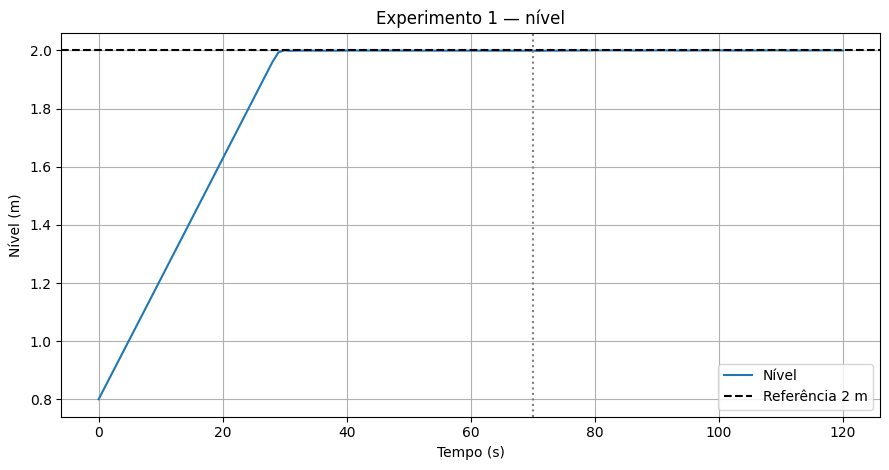

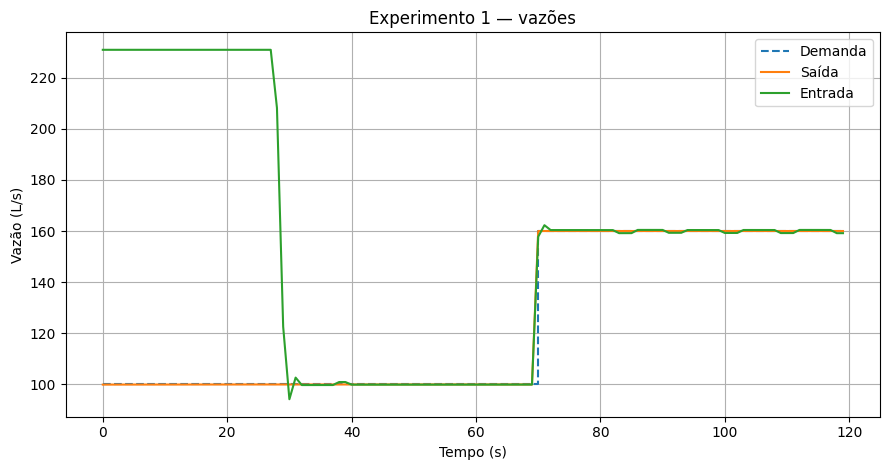

In [26]:
resultado_1_tanque = simular_1_tanque()

## Experimento 1 — um tanque com regularização.

Após executar o caso-base **sem regularização**, esta seção repete o mesmo experimento com um termo adicional na função objetivo. O modelo físico, a demanda, o horizonte, as restrições, o chute inicial e o método SLSQP permanecem iguais. A única mudança é a penalização das variações das tensões.

**Função objetivo regularizada:**

\[
\boxed{\begin{aligned}
\min J_{1,\mathrm{reg}}={}&\sum_{j=1}^{N_p}(h_j-h_{ref})^2
+10^5s_{dem}^2+10^8s_{niv}^2\\
&+\lambda_u\sum_{j=1}^{N_p}\left[
(u_{e,j}-u_{e,j-1})^2+(u_{s,j}-u_{s,j-1})^2
\right].
\end{aligned}}
\]

Foi adotado inicialmente \(\lambda_u = 10^{-3}\)\ ,valor usado no ensaio MATLAB. Os comandos do instante anterior, \(u_{e,0}\) e \(u_{s,0}\), são os últimos valores efetivamente aplicados.

**Sujeito às mesmas restrições do caso sem regularização:**

\[
\begin{aligned}
q_{e,j}&=A_Eu_{e,j}+B_E, & q_{s,j}&=K_su_{s,j}\sqrt{h_{j-1}},\\
h_j&=h_{j-1}+\frac{\Delta t}{A}(q_{e,j}-q_{s,j}), & h_0&=h(k),\\
h_{min}-s_{niv}&\le h_j\le h_{max}+s_{niv},\\
2&\le u_{e,j},u_{s,j}\le10,\\
q_{e,j}&\le0.25, & q_{s,j}&\le0.3543,\\
q_d(k)-s_{dem}&\le q_{s,j}\le q_d(k)+s_{dem},\\
0&\le s_{dem}\le2, & 0&\le s_{niv}\le5.
\end{aligned}
\]

A regularização **não substitui nem altera as restrições**: ela acrescenta um custo às mudanças entre comandos consecutivos. Assim, uma variação brusca continua permitida, mas só será escolhida quando a melhora nos demais termos da função objetivo compensar a penalização.

**Justificativa:** a função objetivo original avalia o erro de nível e as folgas operacionais, mas não penaliza diretamente a movimentação das válvulas. Nos ensaios MATLAB com `fmincon` conectado ao Factory I/O, a tensão da válvula de entrada apresentou oscilações repetidas de grande amplitude. O termo de regularização foi acrescentado para favorecer sinais de atuação mais suaves e evitar mudanças desnecessárias. Isso representa uma preferência de operação, não um modelo dinâmico nem uma restrição física de velocidade do atuador.

O código abaixo é uma segunda implementação do experimento de um tanque. A função original `simular_1_tanque()` continua representando o caso sem regularização.

In [27]:
LAMBDA_U= 1e-3  # Peso da regularizacao; aumente para penalizar mais as variacoes.

# EXPERIMENTO 1 — UM TANQUE
# =====================================================================
def simular_1_tanque_regularizado(lambda_u=LAMBDA_U):
    cfg = CENARIO_1_TANQUE
    pesos = PESOS_OBJETIVO["um_tanque"]
    T = cfg["duracao"]
    demanda = montar_demanda(cfg["blocos_demanda"])

    # Estado inicial e histórico.
    h = float(cfg["nivel_inicial"])
    u_ant = np.asarray(cfg["comando_inicial"], dtype=float)
    H = [h]
    Qe, Qs, Ue, Us = [], [], [], []

    for k in range(T):
        qd = demanda[k]

        # Vetor de decisão:
        # [ue(1..NP), us(1..NP), s_dem, s_niv].
        # O otimizador escolhe uma sequência futura de comandos e folgas.
        x0 = np.r_[
            np.full(NP, u_ant[0]),
            np.full(NP, u_ant[1]),
            qd,
            max(0.0, H_MIN - h + 0.05),
        ]

        # -------------------------------------------------------------
        # FORMULAÇÃO DO PROBLEMA: PREVISÃO, OBJETIVO E RESTRIÇÕES
        # -------------------------------------------------------------
        def decompor_decisao(x):
            ue = x[:NP]
            us = x[NP:2*NP]
            s_dem, s_niv = x[-2:]
            return ue, us, s_dem, s_niv

        def funcao_objetivo(x):
            ue, us, s_dem, s_niv = decompor_decisao(x)
            hp, _, _, _, _ = prever_um_tanque_euler(h, ue, us, DT)

            # Termos da função objetivo:
            # 1) manter os níveis previstos perto de H_REF;
            # 2) penalizar a folga usada no atendimento da demanda;
            # 3) penalizar a folga usada nos limites de nível.
            erro_nivel = pesos["nivel"] * np.sum((hp[1:] - H_REF)**2)
            penalidade_demanda = pesos["demanda"] * s_dem**2
            penalidade_nivel = pesos["nivel_slack"] * s_niv**2
            # Regularizacao de Tikhonov: penaliza variacoes entre comandos
            # consecutivos, incluindo a transicao a partir do comando anterior.
            delta_ue = np.diff(np.r_[u_ant[0], ue])
            delta_us = np.diff(np.r_[u_ant[1], us])
            penalidade_tikhonov = lambda_u * (
                np.sum(delta_ue**2) + np.sum(delta_us**2)
            )

            return (erro_nivel + penalidade_demanda + penalidade_nivel
                    + penalidade_tikhonov)

        def restricoes(x):
            ue, us, s_dem, s_niv = decompor_decisao(x)
            hp, _, qs, _, _ = prever_um_tanque_euler(h, ue, us, DT)
            qe = vazao_entrada(ue)

            # No formato do SciPy, cada desigualdade deve ser >= 0.
            return np.r_[
                hp[1:] + s_niv - H_MIN,       # nível >= mínimo (com folga)
                H_MAX - (hp[1:] - s_niv),     # nível <= máximo (com folga)
                QS_MAX_IND - qs,              # vazão de saída máxima
                qd + s_dem - qs,              # vazão atende limite inferior
                qs - (qd - s_dem),            # vazão atende limite superior
                QE_MAX_IND - qe,              # vazão de entrada máxima
            ]

        # Limites das variáveis: tensões primeiro, depois as duas folgas.
        bounds = (
            [(U_MIN, U_MAX)] * (2*NP)
            + [(0.0, 2.0), (0.0, 5.0)]
        )
        constraints = [{"type": "ineq", "fun": restricoes}]

        # -------------------------------------------------------------
        # MÉTODO DE OTIMIZAÇÃO: SLSQP (configurado em configuracao.py)
        # -------------------------------------------------------------
        resultado = resolver_slsqp(
            funcao_objetivo,
            x0,
            bounds,
            constraints,
            maxiter=SLSQP["maxiter_1_tanque"],
            nome_problema=f"1 tanque, instante {k}",
        )

        # Aplica apenas o primeiro comando da sequência otimizada.
        ue_aplicado = float(resultado.x[0])
        us_aplicado = float(resultado.x[NP])
        Qe.append(float(vazao_entrada(ue_aplicado)) * 1000.0)  # L/s
        Qs.append(float(vazao_saida(h, us_aplicado)) * 1000.0) # L/s
        Ue.append(ue_aplicado)
        Us.append(us_aplicado)

        # A planta simulada avança com RK4; depois o problema é resolvido de novo.
        h = integrar_rk4(h, ue_aplicado, us_aplicado, DT)
        H.append(h)
        u_ant = np.array([ue_aplicado, us_aplicado])

    # Gráficos do experimento.
    t = np.arange(T + 1)
    td = np.arange(T)

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.plot(t, H, label="Nível")
    ax.axhline(H_REF, ls="--", c="black", label=f"Referência {H_REF:g} m")
    instante_mudanca_demanda = cfg["blocos_demanda"][0][0]
    ax.axvline(instante_mudanca_demanda, ls=":", c="gray")
    ax.set(xlabel="Tempo (s)", ylabel="Nível (m)", title="Experimento 1 — nível")
    ax.grid(); ax.legend(); fig.tight_layout()

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.step(td, demanda * 1000, where="post", ls="--", label="Demanda")
    ax.plot(td, Qs, label="Saída")
    ax.plot(td, Qe, label="Entrada")
    ax.set(xlabel="Tempo (s)", ylabel="Vazão (L/s)", title="Experimento 1 — vazões")
    ax.grid(); ax.legend(); fig.tight_layout()

    return (t, np.asarray(H), td, np.asarray(Qe), np.asarray(Qs),
            np.asarray(Ue), np.asarray(Us))


### Executar o experimento regularizado e comparar os comandos

A célula seguinte executa novamente o cenário de um tanque com \(\lambda_u=10^{-3}\). Em seguida, compara as tensões de entrada e saída do caso sem regularização e do caso regularizado.

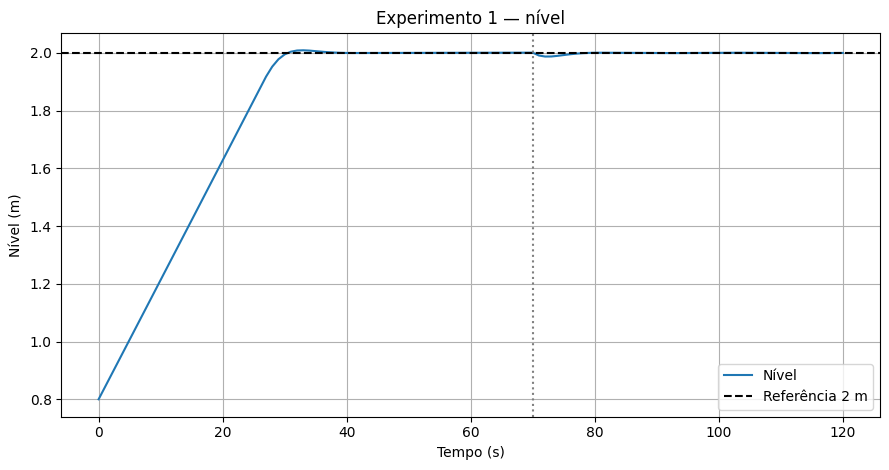

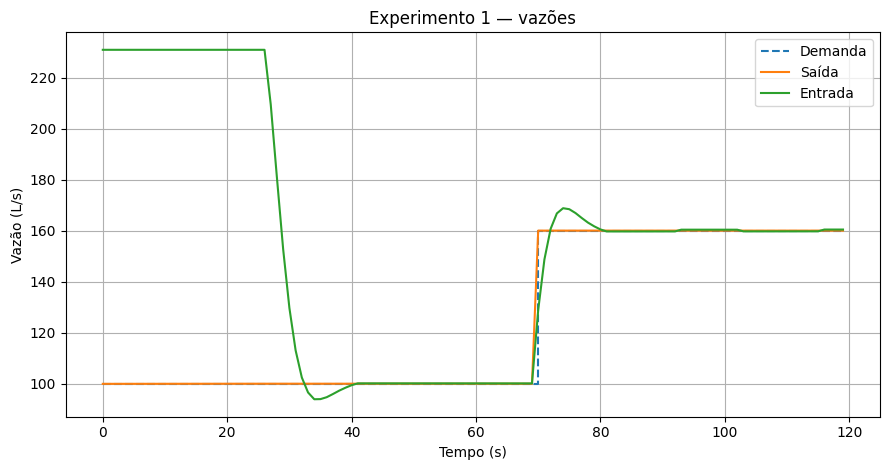

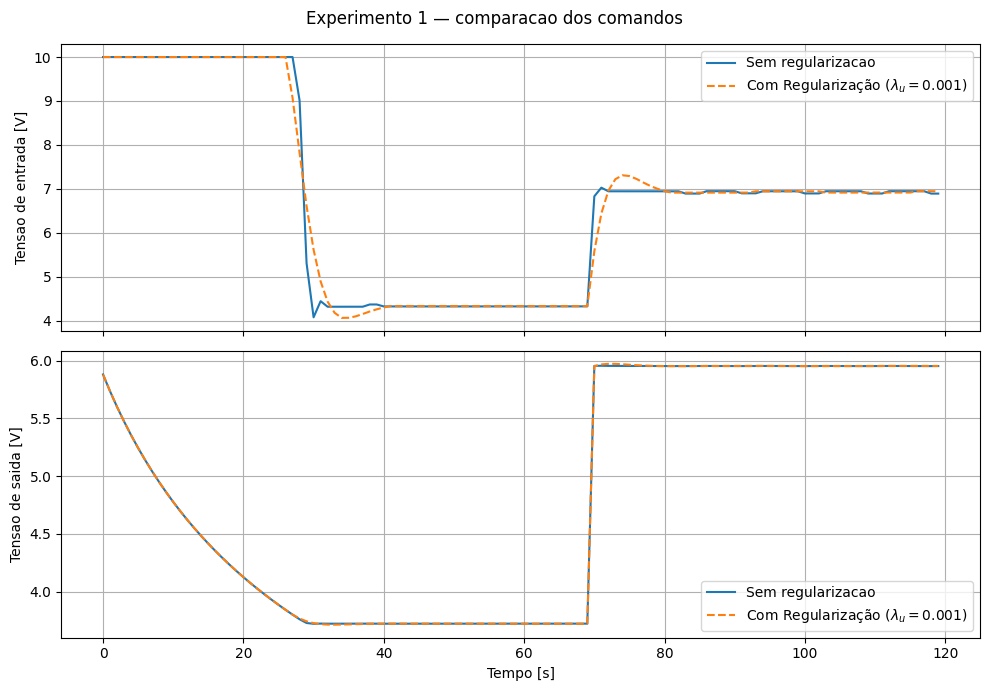

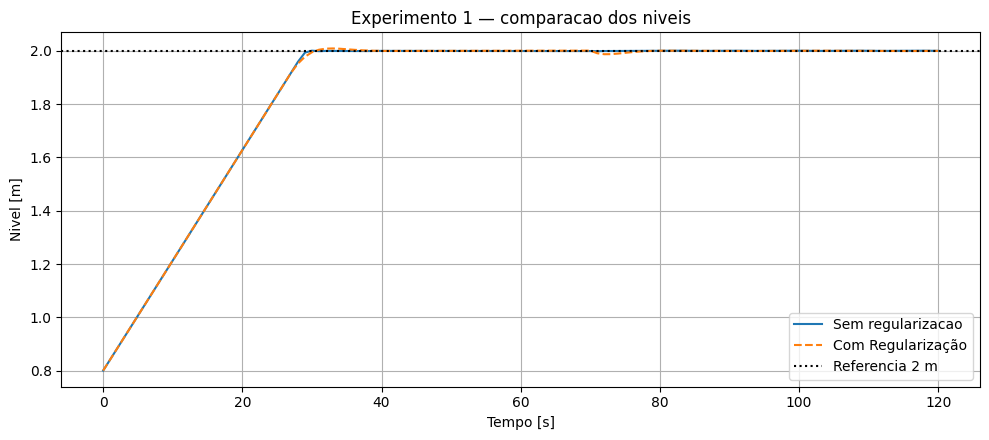

In [30]:
# Execucao do caso com regularizacao.
resultado_1_tanque_regularizado = simular_1_tanque_regularizado()

# Os dois resultados possuem: tempo, nivel, tempo de vazao, vazoes de entrada/saida,
# comandos de entrada e comandos de saida.
t0, h0, td0, qe0, qs0, ue0, us0 = resultado_1_tanque
t1, h1, td1, qe1, qs1, ue1, us1 = resultado_1_tanque_regularizado

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(td0, ue0, label="Sem regularizacao")
ax[0].plot(td1, ue1, "--", label=fr"Com Regularização ($\lambda_u={LAMBDA_U:g}$)")
ax[0].set_ylabel("Tensao de entrada [V]")
ax[0].grid(True); ax[0].legend()
ax[1].plot(td0, us0, label="Sem regularizacao")
ax[1].plot(td1, us1, "--", label=fr"Com Regularização ($\lambda_u={LAMBDA_U:g}$)")
ax[1].set_ylabel("Tensao de saida [V]")
ax[1].set_xlabel("Tempo [s]")
ax[1].grid(True); ax[1].legend()
fig.suptitle("Experimento 1 — comparacao dos comandos")
fig.tight_layout()
plt.show()

# Comparacao dos niveis previstos na simulacao da planta.
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(t0, h0, label="Sem regularizacao")
ax.plot(t1, h1, "--", label="Com Regularização")
ax.axhline(H_REF, color="black", linestyle=":", label=f"Referencia {H_REF:g} m")
ax.set(xlabel="Tempo [s]", ylabel="Nivel [m]", title="Experimento 1 — comparacao dos niveis")
ax.grid(True); ax.legend(); fig.tight_layout(); plt.show()


## Experimento 2 — Dois tanques

**Função objetivo:**

\[
\begin{aligned}
\min J_2={}&\sum_{j=1}^{N_p}\left[100(h_{1,j}-h_{ref})^2+10(h_{2,j}-h_{ref})^2\right]\\
&+10^6s_{dem,1}^2+20\sum_{j=1}^{N_p}s_{dem,2,j}^2+10^8s_{niv}^2.
\end{aligned}
\]

**Sujeito a, para cada tanque \(i\in\{1,2\}\):**

\[
\begin{aligned}
q_{e,i,j}&=A_Eu_{e,i,j}+B_E, & q_{s,i,j}&=K_su_{s,i,j}\sqrt{h_{i,j-1}},\\
h_{i,j}&=h_{i,j-1}+\frac{\Delta t}{A}(q_{e,i,j}-q_{s,i,j}),\\
h_{min}-s_{niv}&\le h_{i,j}\le h_{max}+s_{niv},\\
2&\le u_{e,i,j},u_{s,i,j}\le10,\\
q_{e,i,j}&\le0.25, &q_{s,i,j}&\le0.3543,\\
q_{e,1,j}+q_{e,2,j}&\le0.40,\\
q_{d,1}(k)-s_{dem,1}&\le q_{s,1,j}\le q_{d,1}(k)+s_{dem,1},\\
q_{d,2}(k)-s_{dem,2,j}&\le q_{s,2,j}\le q_{d,2}(k),\\
0&\le s_{dem,1},s_{dem,2,j}\le2, &0&\le s_{niv}\le5.
\end{aligned}
\]


In [15]:
# =====================================================================
# EXPERIMENTO 2 — DOIS TANQUES COM ENTRADA COMPARTILHADA
# =====================================================================
def simular_2_tanques():
    cfg = CENARIO_2_TANQUES
    pesos = PESOS_OBJETIVO["dois_tanques"]
    T = cfg["duracao"]
    d1 = montar_demanda(cfg["blocos_demanda_t1"]) / 1000.0  # L/s -> m³/s
    d2 = montar_demanda(cfg["blocos_demanda_t2"]) / 1000.0

    h = np.asarray(cfg["niveis_iniciais"], dtype=float)
    u_ant = np.asarray(cfg["comandos_iniciais"], dtype=float)
    H = [h.copy()]
    Qe, Qs = [], []

    for k in range(T):
        qd = np.array([d1[k], d2[k]])

        # Vetor de decisão:
        # [ue1,ue2,us1,us2 em cada estágio; s_dem1; s_dem2(1..NP); s_niv].
        # A folga de demanda do tanque 1 é escalar; a do tanque 2 é por estágio.
        x0 = np.r_[
            np.tile(u_ant, NP),
            0.0,
            np.zeros(NP),
            max(0.0, H_MIN - np.min(h) + 0.05),
        ]

        # -------------------------------------------------------------
        # FORMULAÇÃO DO PROBLEMA: PREVISÃO, OBJETIVO E RESTRIÇÕES
        # -------------------------------------------------------------
        def decompor_decisao(x):
            U = x[:4*NP].reshape(NP, 4)
            s_dem1 = x[4*NP]
            s_dem2 = x[4*NP + 1:5*NP + 1]
            s_niv = x[-1]
            return U, s_dem1, s_dem2, s_niv

        def funcao_objetivo(x):
            U, s_dem1, s_dem2, s_niv = decompor_decisao(x)
            hp, _, _, _ = prever_dois_tanques_euler(h, U, DT)

            # Pesos maiores fazem o algoritmo priorizar mais aquele termo.
            erro_nivel_t1 = pesos["nivel_t1"] * np.sum((hp[1:, 0] - H_REF)**2)
            erro_nivel_t2 = pesos["nivel_t2"] * np.sum((hp[1:, 1] - H_REF)**2)
            penalidade_demanda_t1 = pesos["demanda_t1"] * s_dem1**2
            penalidade_demanda_t2 = pesos["demanda_t2"] * np.sum(s_dem2**2)
            penalidade_nivel = pesos["nivel_slack"] * s_niv**2

            return (erro_nivel_t1 + erro_nivel_t2
                    + penalidade_demanda_t1 + penalidade_demanda_t2
                    + penalidade_nivel)

        def restricoes(x):
            U, s_dem1, s_dem2, s_niv = decompor_decisao(x)
            hp, qi, qo, _ = prever_dois_tanques_euler(h, U, DT)
            capacidade_compartilhada = LIMITES["QE_MAX_COMP"]

            return np.r_[
                (hp[1:] + s_niv - H_MIN).ravel(),
                (H_MAX - (hp[1:] - s_niv)).ravel(),
                (QS_MAX_IND - qo).ravel(),
                (QE_MAX_IND - qi).ravel(),
                capacidade_compartilhada - qi.sum(axis=1),
                qo[:, 0] - (qd[0] + s_dem1),
                (qd[0] - s_dem1) - qo[:, 0],
                qd[1] - qo[:, 1],
                qo[:, 1] - (qd[1] - s_dem2),
            ]

        # Limites das variáveis: 4*NP tensões, s_dem1, NP folgas s_dem2 e s_niv.
        bounds = (
            [(U_MIN, U_MAX)] * (4*NP)
            + [(0.0, 2.0)]
            + [(0.0, 2.0)] * NP
            + [(0.0, 5.0)]
        )
        constraints = [{"type": "ineq", "fun": restricoes}]

        # -------------------------------------------------------------
        # MÉTODO DE OTIMIZAÇÃO: SLSQP (configurado em configuracao.py)
        # -------------------------------------------------------------
        resultado = resolver_slsqp(
            funcao_objetivo,
            x0,
            bounds,
            constraints,
            maxiter=SLSQP["maxiter_2_tanques"],
            nome_problema=f"2 tanques, instante {k}",
        )

        # Aplica apenas os quatro primeiros comandos: [ue1, ue2, us1, us2].
        U_aplicado = resultado.x[:4]
        ue = U_aplicado[:2]
        us = U_aplicado[2:]
        qin = vazao_entrada(ue)
        qout = vazao_saida(h, us)
        Qe.append(np.asarray(qin) * 1000.0)  # L/s
        Qs.append(np.asarray(qout) * 1000.0) # L/s

        # Atualiza os dois tanques com RK4 e prepara a próxima iteração.
        h = np.array([
            integrar_rk4(h[i], ue[i], us[i], DT) for i in range(2)
        ])
        H.append(h.copy())
        u_ant = U_aplicado.copy()

    # Gráficos do experimento.
    t = np.arange(T + 1)
    td = np.arange(T)
    H = np.asarray(H)
    Qe = np.asarray(Qe)
    Qs = np.asarray(Qs)

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.plot(t, H[:, 0], label="Tanque 1 prioritário")
    ax.plot(t, H[:, 1], label="Tanque 2 secundário")
    ax.axhline(H_REF, ls="--", c="black", label=f"Referência {H_REF:g} m")
    inicio_sobrecarga = cfg["blocos_demanda_t1"][0][0]
    fim_sobrecarga = inicio_sobrecarga + cfg["blocos_demanda_t1"][1][0]
    ax.axvspan(inicio_sobrecarga, fim_sobrecarga, alpha=.12, color="gray", label="Sobrecarga")
    ax.set(xlabel="Tempo (s)", ylabel="Nível (m)", title="Experimento 2 — níveis")
    ax.grid(); ax.legend(); fig.tight_layout()

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.step(td, d1 * 1000, where="post", ls="--", label="Demanda T1")
    ax.plot(td, Qs[:, 0], label="Saída T1")
    ax.step(td, d2 * 1000, where="post", ls="--", label="Demanda T2")
    ax.plot(td, Qs[:, 1], label="Saída T2")
    ax.plot(td, Qe.sum(axis=1), label="Entrada total")
    ax.axhline(LIMITES["QE_MAX_COMP"] * 1000, ls=":", c="black",
               label=f"Limite compartilhado {LIMITES['QE_MAX_COMP']*1000:.0f} L/s")
    ax.set(xlabel="Tempo (s)", ylabel="Vazão (L/s)", title="Experimento 2 — vazões")
    ax.grid(); ax.legend(ncol=2); fig.tight_layout()

    return t, H, td, Qe, Qs


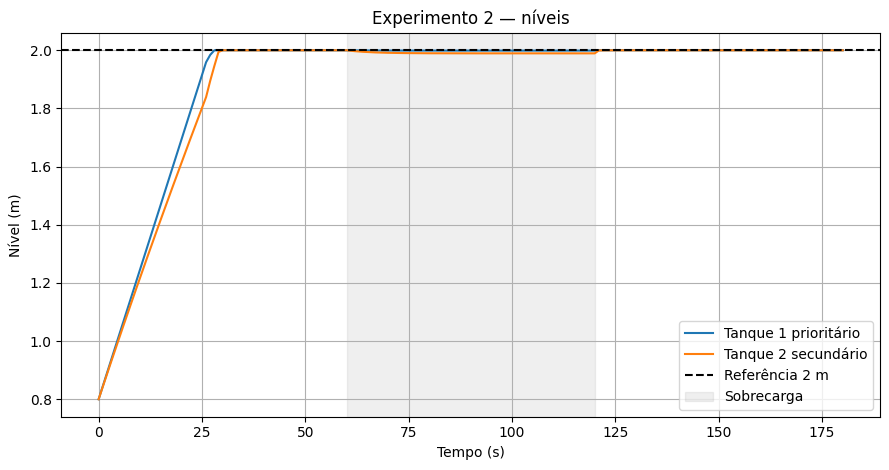

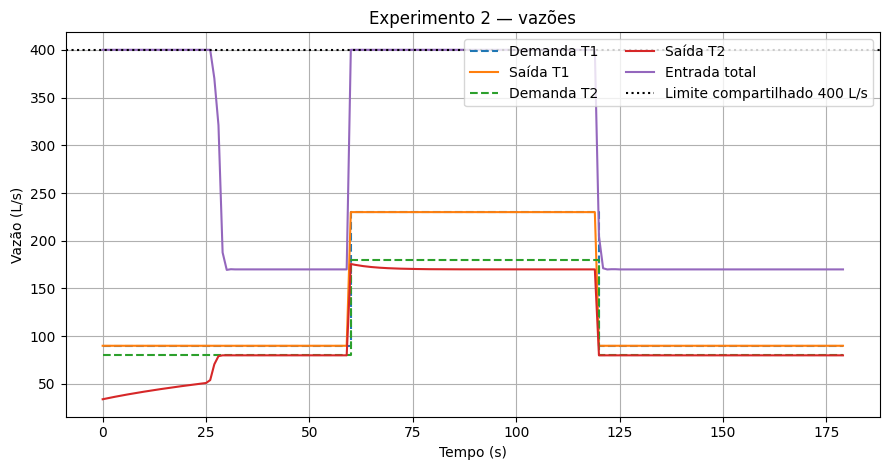

In [31]:
resultado_2_tanques = simular_2_tanques()